# R109 E48 external-GMF displacement analysis

## tl;dr

This notebook compares the same 99 measurable Y-direction intervals in Raw and
R109 E48, checks the files and frame alignment first, and then tests whether the
stability improvement remains visible against prior GMF reruns of pixel-identical
Raw images.

In [1]:
from pathlib import Path
from IPython.display import Markdown, Image, display
import contextlib, importlib.util, io, json
import pandas as pd

package = Path(r"D:\GMM_2_Final\Thesis_MOSR_Evidence\External_GMF_Packages\Pitch1um_Y_100_Raw_Even_R109E48")
analysis_dir = package / "gmf_analysis"
analyzer_path = Path(r"D:\GMM_2_Final\Thesis_MOSR_Evidence\External_GMF_Packages\Pitch1um_Y_100_Raw_Even_R109E48\_tools\analyze_gmf_scores.py")
spec = importlib.util.spec_from_file_location("r109_gmf_analysis", analyzer_path)
analyzer = importlib.util.module_from_spec(spec)
spec.loader.exec_module(analyzer)
with contextlib.redirect_stdout(io.StringIO()):
    analyzer.main()
summary = json.loads((analysis_dir / "analysis_summary.json").read_text(encoding="utf-8"))
raw = summary["current_raw"]
model = summary["r109_e48"]
change = summary["comparison_vs_current_raw"]
display(Markdown(
    f"**Observed result:** R109 reduced Y-step standard deviation by "
    f"{change['y_step_std_reduction_pct']:.1f}%, Y-step mean absolute error by "
    f"{change['y_error_mae_reduction_pct']:.1f}%, and cross-axis standard deviation by "
    f"{change['x_step_std_reduction_pct']:.1f}%. Wrong-direction intervals fell from "
    f"{raw['wrong_direction_steps']} to {model['wrong_direction_steps']}. "
    f"The result is a strong relative stability improvement, but it is not yet an absolute metrology pass."
))

**Observed result:** R109 reduced Y-step standard deviation by 44.7%, Y-step mean absolute error by 52.9%, and cross-axis standard deviation by 36.5%. Wrong-direction intervals fell from 12 to 5. The result is a strong relative stability improvement, but it is not yet an absolute metrology pass.

## Context & Methods

- Source: external `GMF_score.txt` files returned for the prepared Raw and R109 E48 folders.
- Grain: one coordinate per reported frame; 100 coordinates yield 99 consecutive steps.
- `frame_0000.bmp` is the external tool's reference and is absent from both score files.
- The nominal Y step is -8 px, inherited from the established package convention.
- Pixel values are not converted into a formal micrometre claim because this package does not contain a sealed physical calibration.
- Historical Raw and the historical R104 negative control are included only to measure GMF rerun variability; R104 is pixel-identical to Raw in this package.
- Uncertainty uses a paired moving-block bootstrap with blocks of five adjacent intervals.

## Data

In [2]:
quality_rows = []
for arm, checks in summary["data_quality"].items():
    quality_rows.append({"arm": arm, **checks})
quality = pd.DataFrame(quality_rows)
display(quality)
display(pd.DataFrame([summary["pixel_relationships"]]))

,arm,coordinate_rows,frame_indices_exact_1_to_100,duplicate_frame_count,all_numeric_finite,score_positive,scale_plausible_0p9_to_1p1,angle_zero
0,current_raw,100,True,0,True,True,True,True
1,r109_e48,100,True,0,True,True,True,True
2,historical_raw,100,True,0,True,True,True,True
3,historical_r103_e48,100,True,0,True,True,True,True
4,historical_r104_raw_negative_control,100,True,0,True,True,True,True


,same_original_filename_order,same_raw_hashes,historical_r104_is_pixel_identical_to_raw,historical_r103_differs_from_raw_count,current_r109_differs_from_raw_count
0,True,True,True,101,101


## Results

In [3]:
metric_rows = [
    ("Y-step mean (px)", raw["y_step_mean_px"], model["y_step_mean_px"]),
    ("Y-step SD (px)", raw["y_step_std_px"], model["y_step_std_px"]),
    ("Y error MAE (px)", raw["y_error_mae_px"], model["y_error_mae_px"]),
    ("Y error median absolute (px)", raw["y_error_median_abs_px"], model["y_error_median_abs_px"]),
    ("Y error P95 absolute (px)", raw["y_error_p95_abs_px"], model["y_error_p95_abs_px"]),
    ("Cross-axis SD (px)", raw["x_step_std_px"], model["x_step_std_px"]),
    ("Detrended Y coordinate SD (px)", raw["detrended_y_coordinate_std_px"], model["detrended_y_coordinate_std_px"]),
    ("Scale SD", raw["scale_std"], model["scale_std"]),
    ("Wrong-direction steps", raw["wrong_direction_steps"], model["wrong_direction_steps"]),
    ("Within 20% of nominal", raw["within_20pct"], model["within_20pct"]),
    ("Median GMF score", raw["score_median"], model["score_median"]),
    ("Endpoint error (px)", raw["endpoint_error_px"], model["endpoint_error_px"]),
]
comparison_table = pd.DataFrame(metric_rows, columns=["metric", "Raw", "R109 E48"])
display(comparison_table.style.format({"Raw": "{:.4f}", "R109 E48": "{:.4f}"}))

,metric,Raw,R109 E48
0,Y-step mean (px),-7.9998,-8.0457
1,Y-step SD (px),8.2058,4.5382
2,Y error MAE (px),6.3707,2.9990
3,Y error median absolute (px),5.1900,1.6900
4,Y error P95 absolute (px),16.9350,10.5760
5,Cross-axis SD (px),6.8734,4.3633
6,Detrended Y coordinate SD (px),5.6269,3.1476
7,Scale SD,0.0110,0.0058
8,Wrong-direction steps,12.0000,5.0000
9,Within 20% of nominal,0.1515,0.4747


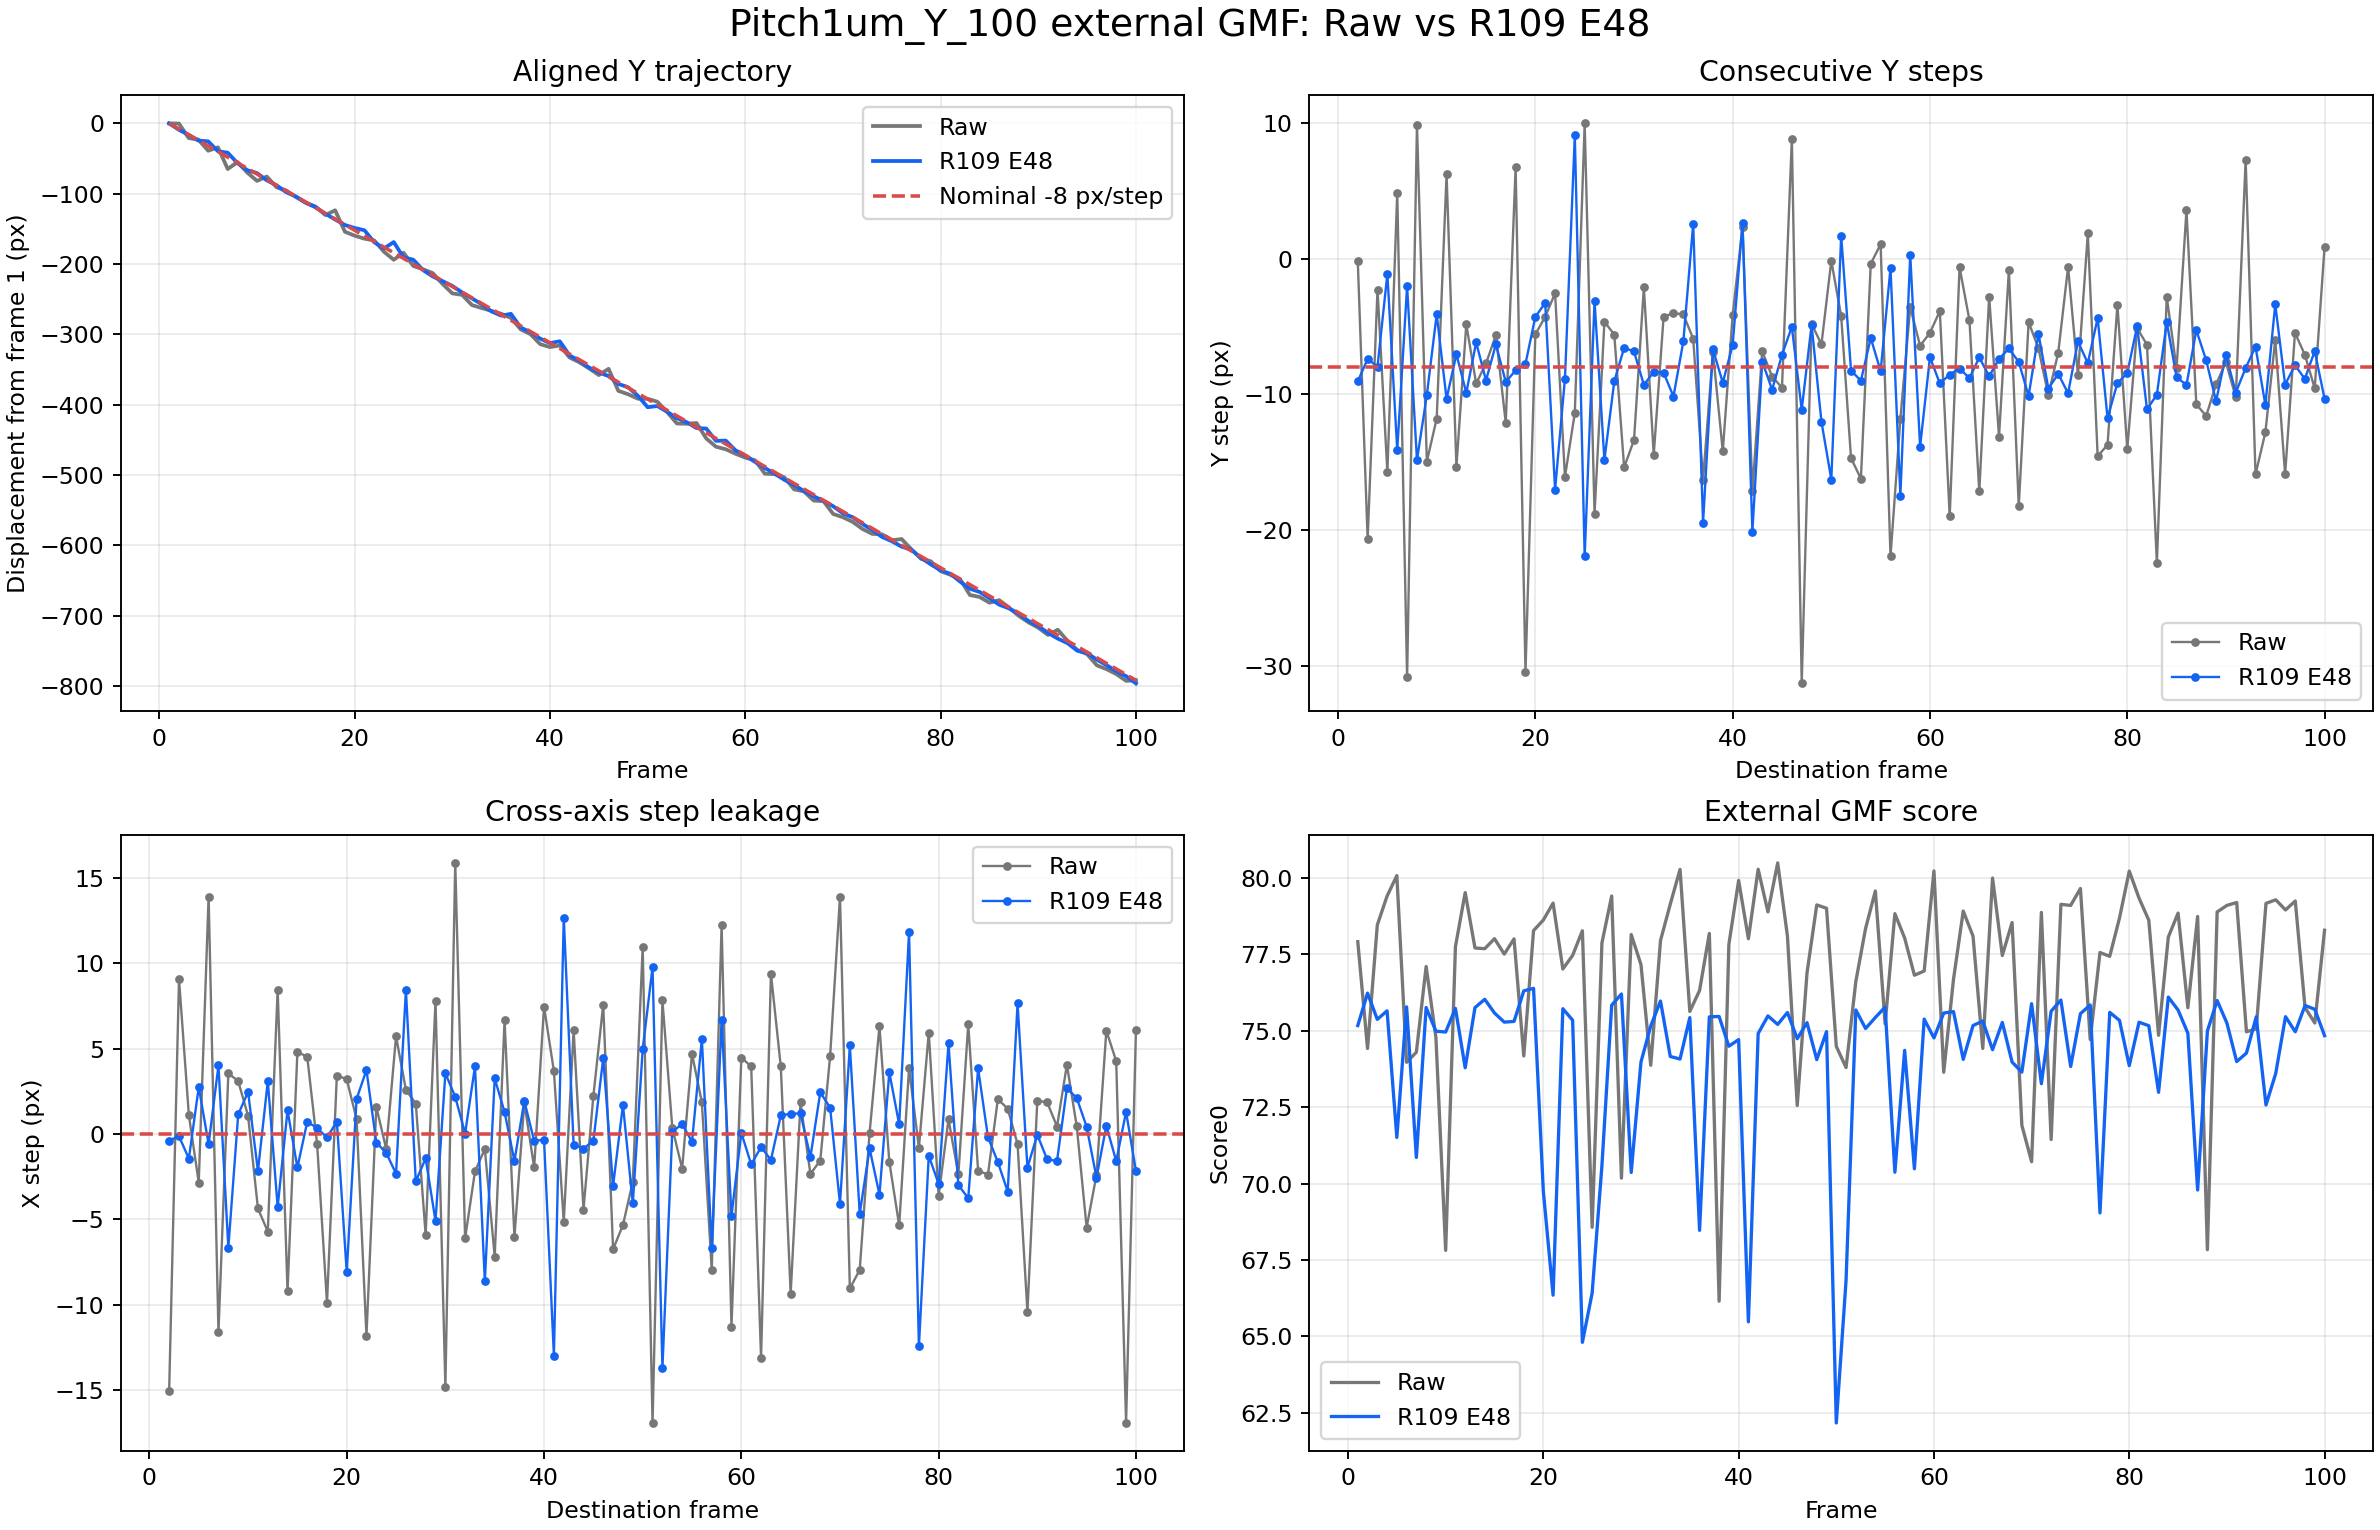

In [4]:
display(Image(filename=str(analysis_dir / "trajectory_step_score.png")))

In [5]:
raw_floor = pd.read_csv(analysis_dir / "raw_equivalent_run_floor.csv", encoding="utf-8-sig")
display(raw_floor[[
    "run", "y_step_std_px", "y_error_mae_px", "x_step_std_px",
    "detrended_y_coordinate_std_px", "score_median"
]])

,run,y_step_std_px,y_error_mae_px,x_step_std_px,detrended_y_coordinate_std_px,score_median
0,historical_raw,6.699079,5.023434,6.499926,4.720907,79.10980
1,historical_r104_raw_negative_control,8.160289,6.481313,7.429483,5.439478,78.63995
2,current_raw,8.205826,6.370707,6.873371,5.626938,77.99935


In [6]:
bootstrap_rows = []
for metric in ("y_step_std", "y_error_mae", "x_step_std"):
    item = summary["paired_moving_block_bootstrap"][metric]
    bootstrap_rows.append({"metric": metric, **item})
display(pd.DataFrame(bootstrap_rows).style.format({
    "ratio_p025": "{:.3f}", "ratio_median": "{:.3f}",
    "ratio_p975": "{:.3f}", "fraction_ratio_ge_1": "{:.5f}"
}))

,metric,ratio_p025,ratio_median,ratio_p975,fraction_ratio_ge_1
0,y_step_std,0.396,0.557,0.746,0.00000
1,y_error_mae,0.353,0.480,0.637,0.00000
2,x_step_std,0.503,0.664,0.862,0.00075


In [7]:
outliers = pd.read_csv(analysis_dir / "largest_y_step_errors.csv", encoding="utf-8-sig")
display(outliers[[
    "arm", "outlier_rank", "from_frame", "to_frame", "dx_px", "dy_px",
    "abs_y_error_px", "interval_min_score", "scale_change_abs"
]])

,arm,outlier_rank,from_frame,to_frame,dx_px,dy_px,abs_y_error_px,interval_min_score,scale_change_abs
0,current_raw,1,46,47,-6.76,-31.31,23.31,72.5521,0.014095
1,current_raw,2,6,7,-11.62,-30.87,22.87,73.9630,0.016244
2,current_raw,3,18,19,3.42,-30.50,22.50,74.1701,0.001790
3,current_raw,4,24,25,5.72,9.97,17.97,68.5699,0.024910
4,current_raw,5,7,8,3.55,9.88,17.88,74.2924,0.006520
5,current_raw,6,45,46,7.58,8.83,16.83,72.5521,0.000706
6,current_raw,7,91,92,0.43,7.31,15.31,74.9608,0.013978
7,current_raw,8,17,18,-9.90,6.75,14.75,74.1701,0.009352
8,current_raw,9,82,83,6.42,-22.46,14.46,74.8460,0.015697
9,current_raw,10,10,11,-4.37,6.23,14.23,67.8167,0.024492


In [8]:
score_conditioned = pd.read_csv(analysis_dir / "score_conditioned_summary.csv", encoding="utf-8-sig")
display(score_conditioned[score_conditioned["arm"] == "r109_e48"])

,arm,minimum_interval_score,retained_steps,retained_fraction,y_step_mean_px,y_step_std_px,y_error_mae_px,wrong_direction_steps
6,r109_e48,0.0,99,1.000000,-8.045657,4.538169,2.998990,5
7,r109_e48,65.0,95,0.959596,-8.095684,3.815707,2.609368,3
8,r109_e48,68.0,89,0.898990,-8.089326,3.339212,2.317416,2
9,r109_e48,70.0,82,0.828283,-8.169756,2.914488,2.071951,1
10,r109_e48,72.0,71,0.717172,-8.138592,1.795294,1.461127,0
11,r109_e48,74.0,52,0.525253,-8.204808,1.641994,1.315962,0


## Takeaways

In [9]:
assessment = summary["assessment"]
confidence = summary["r109_confidence_relationship"]
display(Markdown(
    f'''
1. **Relative stability improved strongly.** R109 is lower than the current Raw run and all three Raw-equivalent GMF runs on Y-step SD, cross-axis SD, and detrended coordinate variation.
2. **The gain is not only an endpoint-average effect.** Median absolute Y error fell from {raw['y_error_median_abs_px']:.2f} px to {model['y_error_median_abs_px']:.2f} px, and the robust Y spread fell from {raw['y_step_robust_sigma_px']:.2f} px to {model['y_step_robust_sigma_px']:.2f} px.
3. **Absolute single-step reliability is still insufficient.** Five intervals move in the wrong Y direction and only {model['within_20pct']*100:.1f}% fall within 20% of nominal.
4. **GMF score is an informative confidence signal for R109.** Its correlation with absolute Y error is {confidence['correlation_abs_y_error_vs_interval_min_score']:.3f}; intervals whose two endpoint scores are both at least 72 contain no wrong-direction steps in this run. This is diagnostic evidence, not a newly imposed production threshold.
5. **Caveat:** GMF itself changes coordinates when rerun on pixel-identical images. Confidence is high that R109 improved this package, but only moderate that the exact amount will repeat without a second locked rerun.
'''
))


1. **Relative stability improved strongly.** R109 is lower than the current Raw run and all three Raw-equivalent GMF runs on Y-step SD, cross-axis SD, and detrended coordinate variation.
2. **The gain is not only an endpoint-average effect.** Median absolute Y error fell from 5.19 px to 1.69 px, and the robust Y spread fell from 7.35 px to 2.49 px.
3. **Absolute single-step reliability is still insufficient.** Five intervals move in the wrong Y direction and only 47.5% fall within 20% of nominal.
4. **GMF score is an informative confidence signal for R109.** Its correlation with absolute Y error is -0.788; intervals whose two endpoint scores are both at least 72 contain no wrong-direction steps in this run. This is diagnostic evidence, not a newly imposed production threshold.
5. **Caveat:** GMF itself changes coordinates when rerun on pixel-identical images. Confidence is high that R109 improved this package, but only moderate that the exact amount will repeat without a second locked rerun.
